In [1]:
import sccoda
import scanpy as sc
import pandas as pd
import numpy as np

from sccoda.util import cell_composition_data as dat
from sccoda.util import data_visualization as viz

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.colors import LinearSegmentedColormap

import gc
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)

In [2]:
Heart = sc.read_h5ad("/rwthfs/rz/cluster/hpcwork/noco0013/projects/novo_postdoc/data/Heart_atlas_TB_submission.h5ad")

In [3]:
Heart = Heart.raw.to_adata()

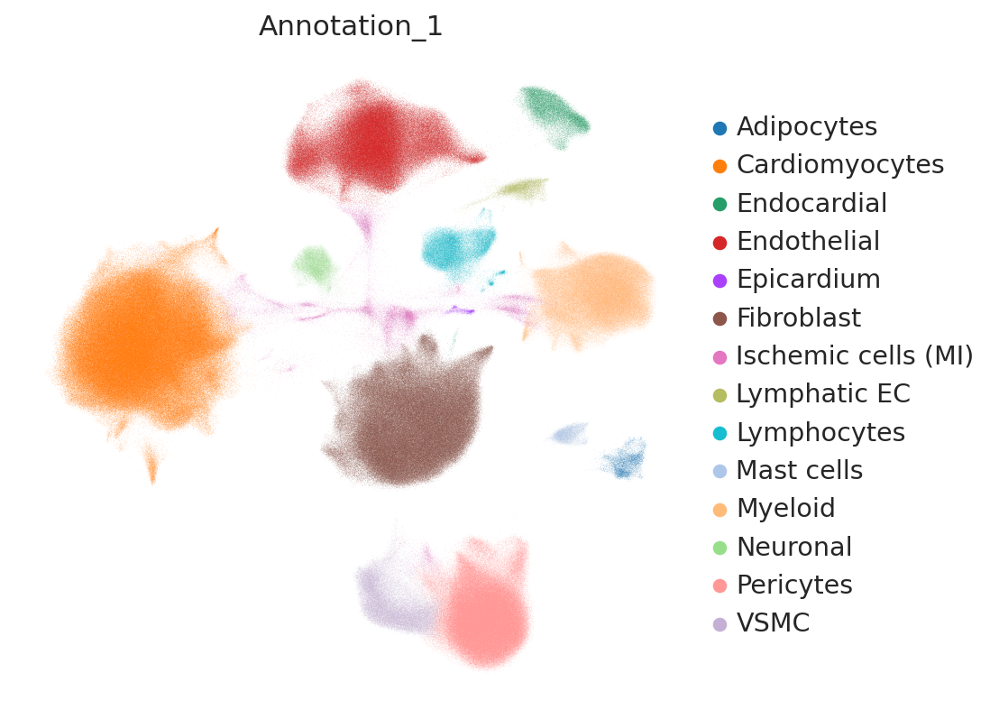

In [4]:
sc.set_figure_params(scanpy=True, dpi=8000, dpi_save=80000)
sc.set_figure_params(figsize=(6, 6))
sc.pl.umap(
    Heart,
    color=["Annotation_1"],
    frameon=False, save="_UMAP_Main_Cell_Types.pdf")

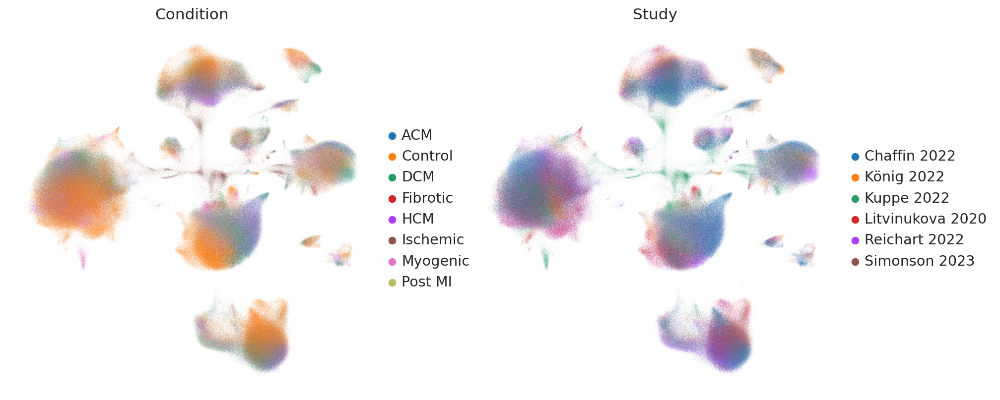

In [5]:
sc.pl.umap(
    Heart, sort_order=['Control', 'ACM', 'DCM', 'HCM', 'Ischemic', 'Myogenic', 'Fibrotic', 'Post MI'],
    color=["Condition", "Study"],
    frameon=False, ncols=2)#,
    #save="_UMAP_Condition_Study.pdf")

In [6]:
Heart = Heart[~(Heart.obs["Subclustering"].isin(['Discard OR LINGO1 cardiomyocytes #1', 'Discard', 'Fibroblast (APOD/E)', 'Cardiomyocytes (LINGO1)']))]
Heart = Heart[~(Heart.obs["Patient_Cluster"].isin(['CTRL_3']))]

In [7]:
gc.collect()

12560

In [8]:
# Use Annotation_1 for colormap of scCODA
Heart.obs["Annotation_1"] = Heart.obs["Annotation_1"].astype("category")
categories = Heart.obs["Annotation_1"].cat.categories
color_list = Heart.uns["Annotation_1_colors"]
cmap = ListedColormap(color_list, name="annotation1_cmap")

/w0/tmp/slurm_uv525372.61622081/ipykernel_2808228/2894280991.py:2: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  Heart.obs["Annotation_1"] = Heart.obs["Annotation_1"].astype("category")


In [9]:
cross_table = pd.crosstab(index=[Heart.obs["Donor"], Heart.obs["Condition"]], columns=Heart.obs["Annotation_1"])
cell_counts = cross_table.reset_index()
compositions = dat.from_pandas(cell_counts, covariate_columns=["Donor", "Condition"])

In [10]:
viz.stacked_barplot(compositions, cmap=cmap, level_order=['Control', 'ACM', 'DCM', 'HCM', 'Ischemic', 'Myogenic', 'Fibrotic', 'Post MI'], feature_name="Condition", dpi=600)

ax = plt.gca()
for side in ["top", "right", "bottom"]:
    ax.spines[side].set_visible(False)
ax.tick_params(left=True, bottom=False)
plt.savefig('Composition_Main_Cell_Types.pdf', format='pdf', bbox_inches='tight')
plt.show()


In [15]:
gc.collect()
subset_H_DCM = Heart[Heart.obs["Study"].isin(["Chaffin 2022", "König 2022", "Reichart 2022"]), :]
subset_H_DCM = subset_H_DCM[subset_H_DCM.obs["Condition"].isin(["Control", "DCM"]), :]
subset_H_DCM.obs["Condition_H_DCM"] = subset_H_DCM.obs["Condition"].astype(str) + "_" + subset_H_DCM.obs["Donor"].astype(str)

cross_table = pd.crosstab(index=[subset_H_DCM.obs["Condition_H_DCM"], subset_H_DCM.obs["Condition"]], columns=subset_H_DCM.obs["Annotation_1"])
cell_counts = cross_table.reset_index()
compositions = dat.from_pandas(cell_counts, covariate_columns=["Condition_H_DCM", "Condition"])

compositions.obs["Condition"] = compositions.obs["Condition"].astype("category")
compositions.obs["Condition"] = compositions.obs["Condition"].cat.set_categories(
    sorted(compositions.obs["Condition"].unique()), ordered=True
)

viz.stacked_barplot(compositions, cmap=cmap, feature_name="Condition_H_DCM", figsize=(18,6), dpi=600)
ax = plt.gca()
for side in ["top", "right", "bottom"]:
    ax.spines[side].set_visible(False)
ax.tick_params(left=True, bottom=False)
#plt.savefig('Composition_Main_Cell_Types_Donors.pdf', format='pdf', bbox_inches='tight')
plt.show()

Pericytes


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

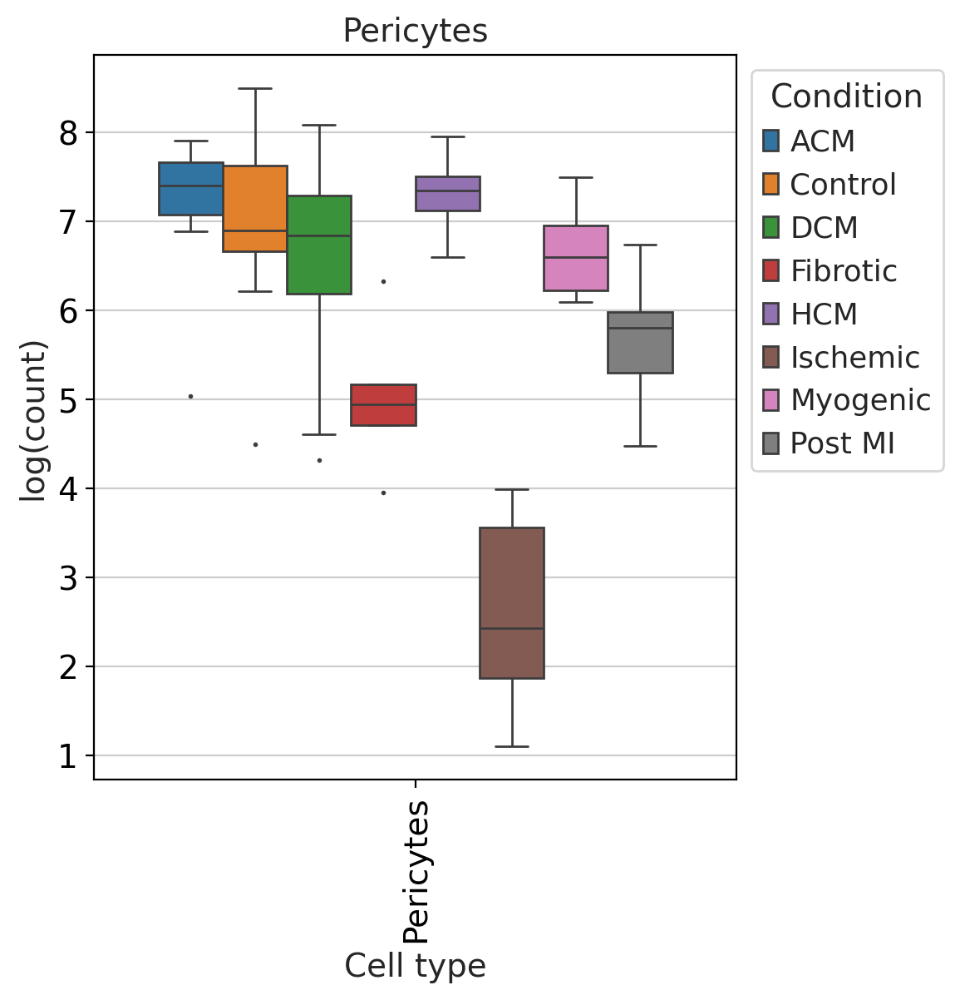

Cardiomyocytes


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

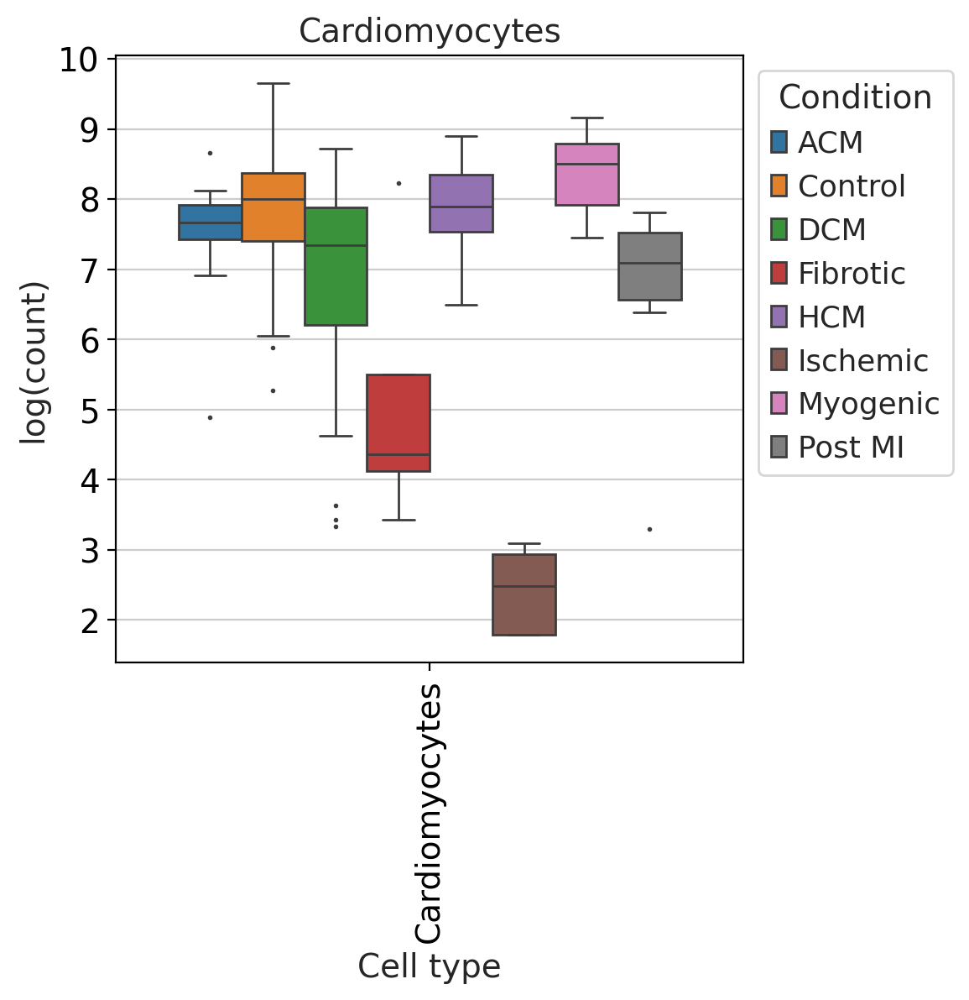

Lymphatic EC


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

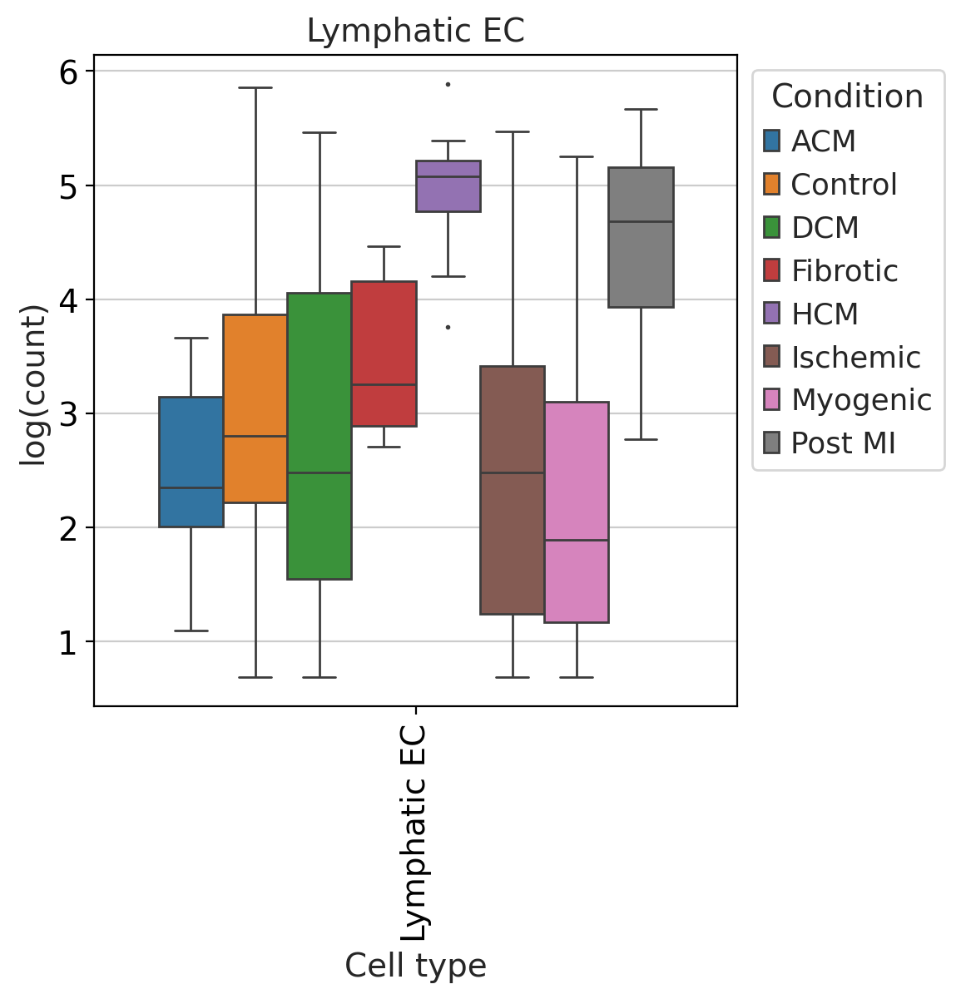

Fibroblast


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

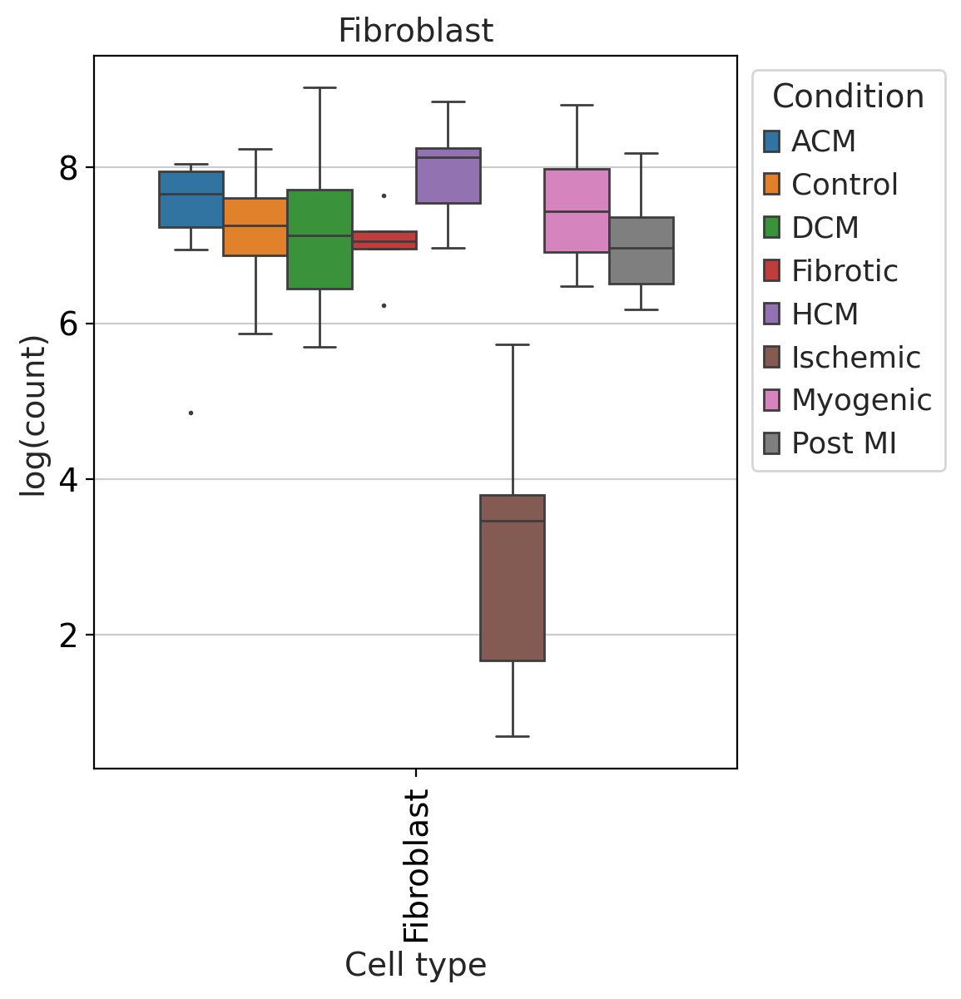

Lymphocytes


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

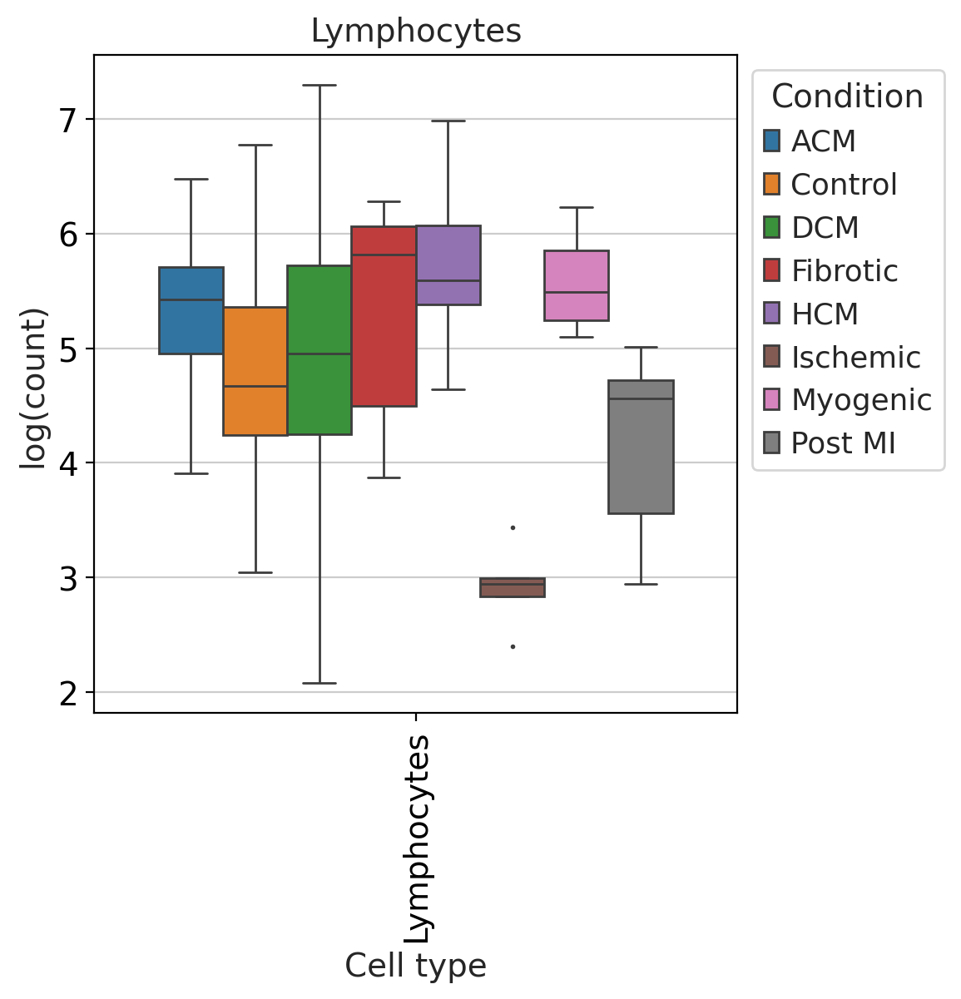

Endothelial


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

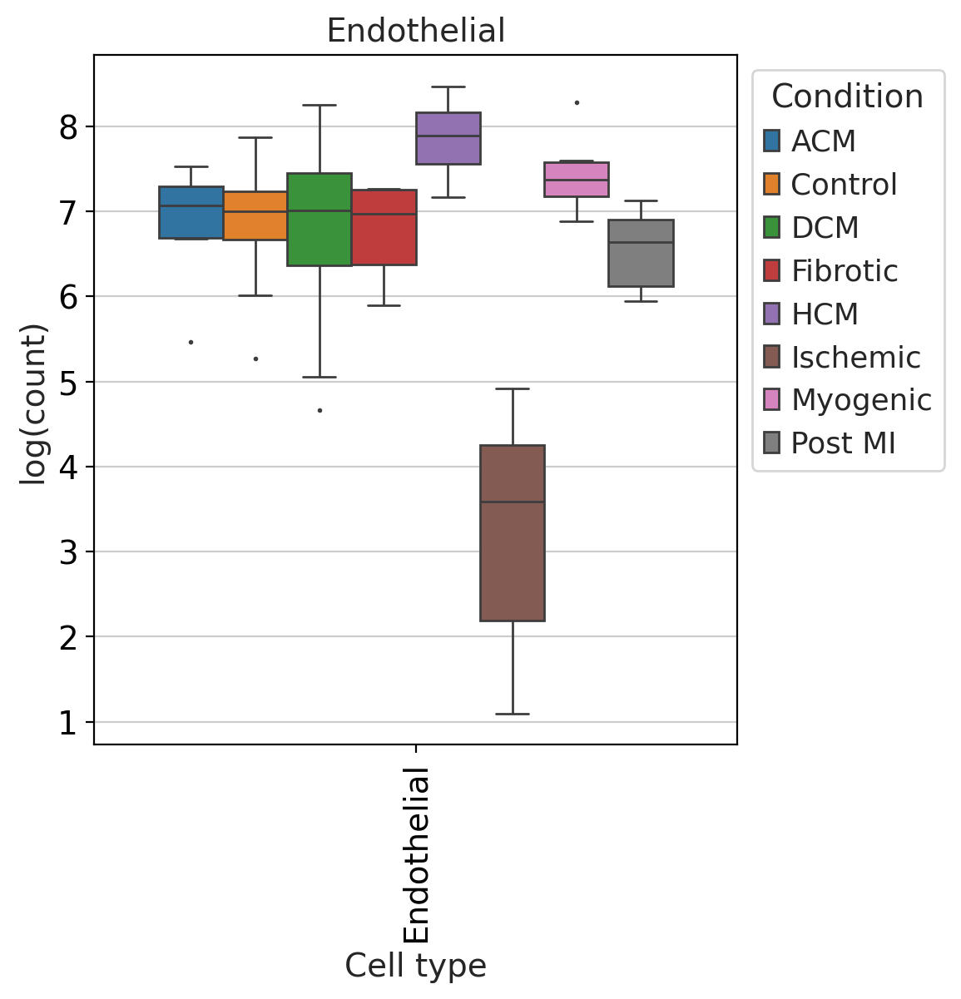

Mast cells


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

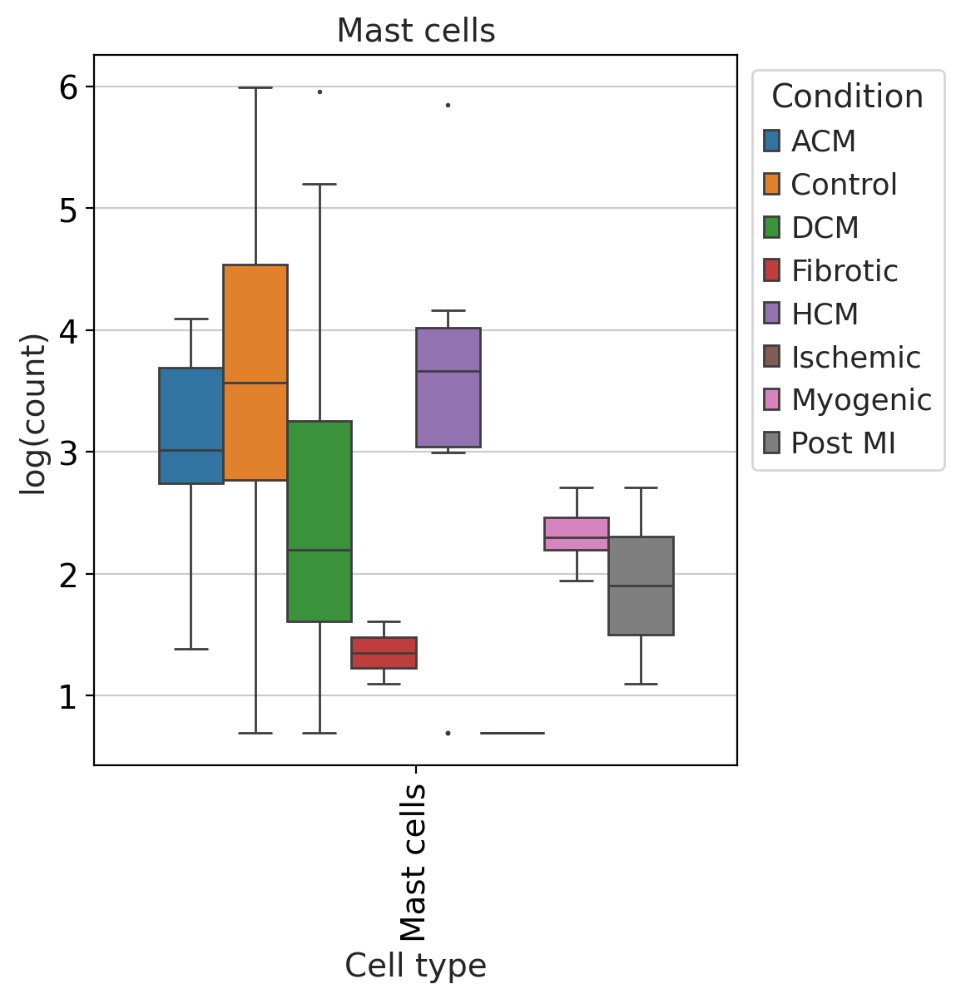

Neuronal


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

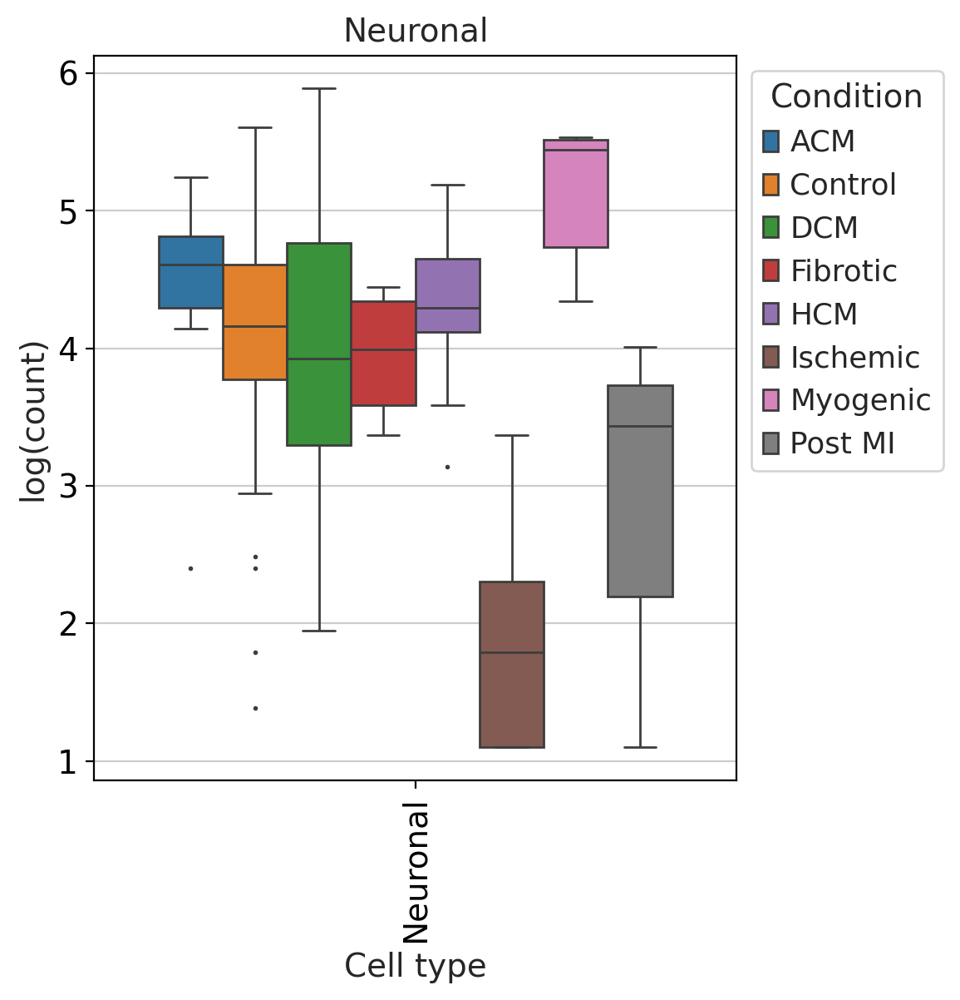

VSMC


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

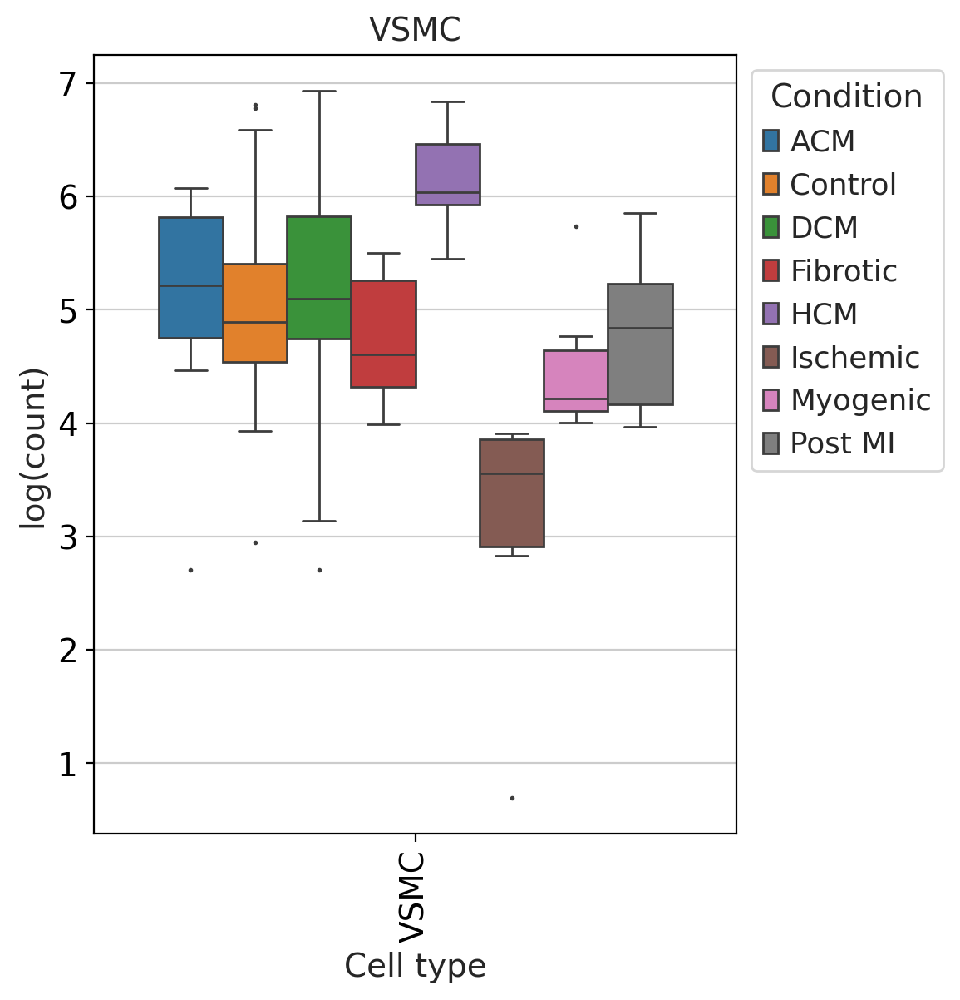

Myeloid


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

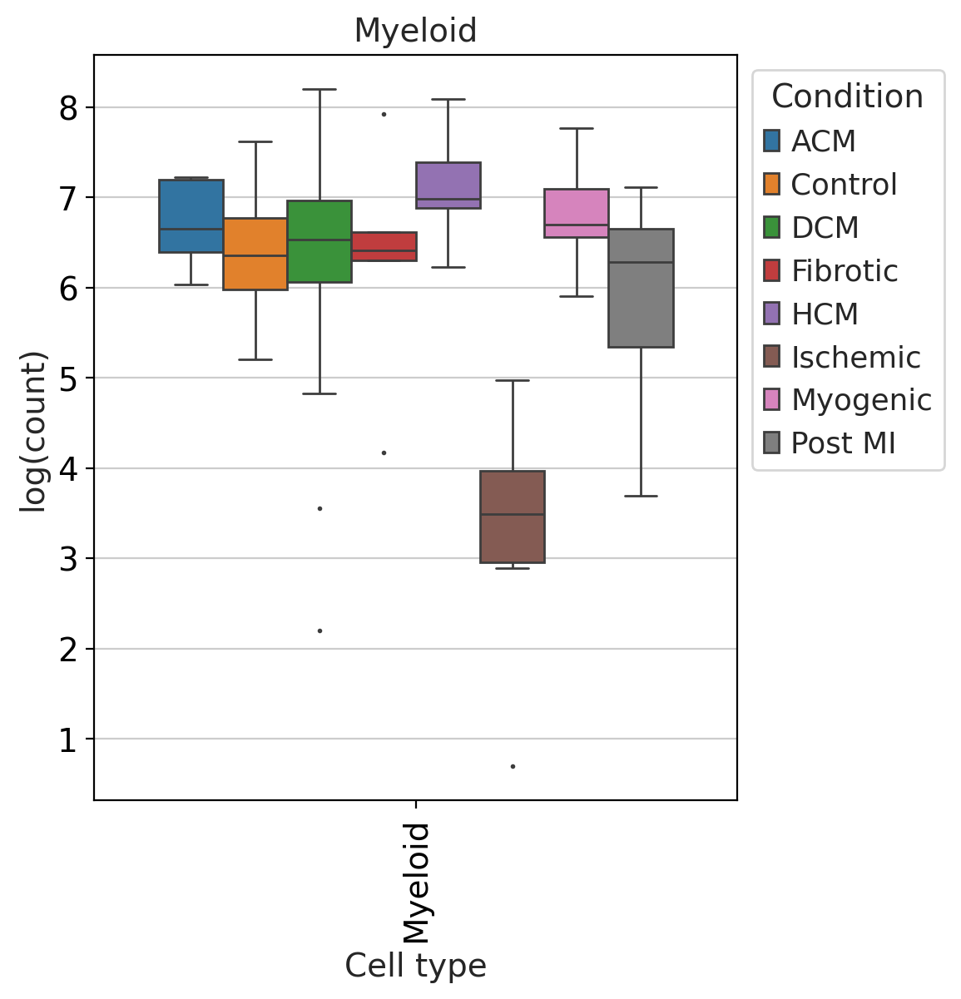

Adipocytes


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

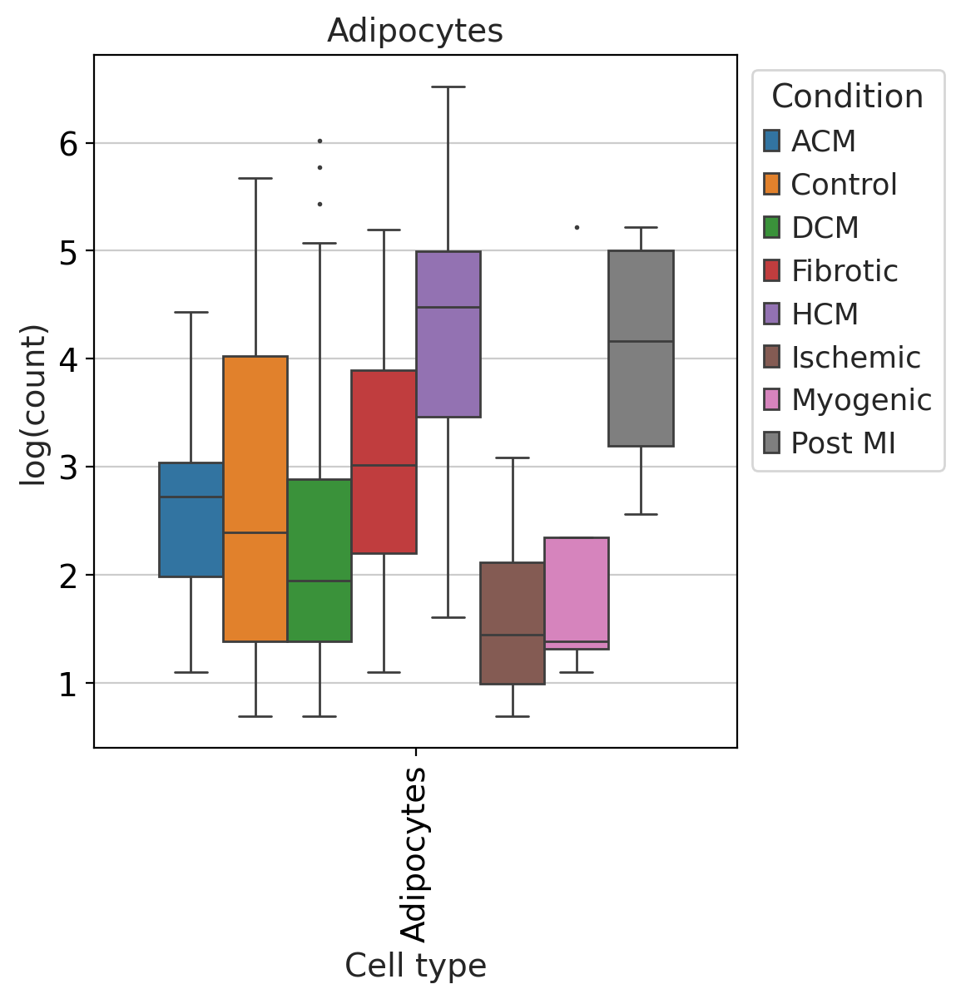

Ischemic cells (MI)


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

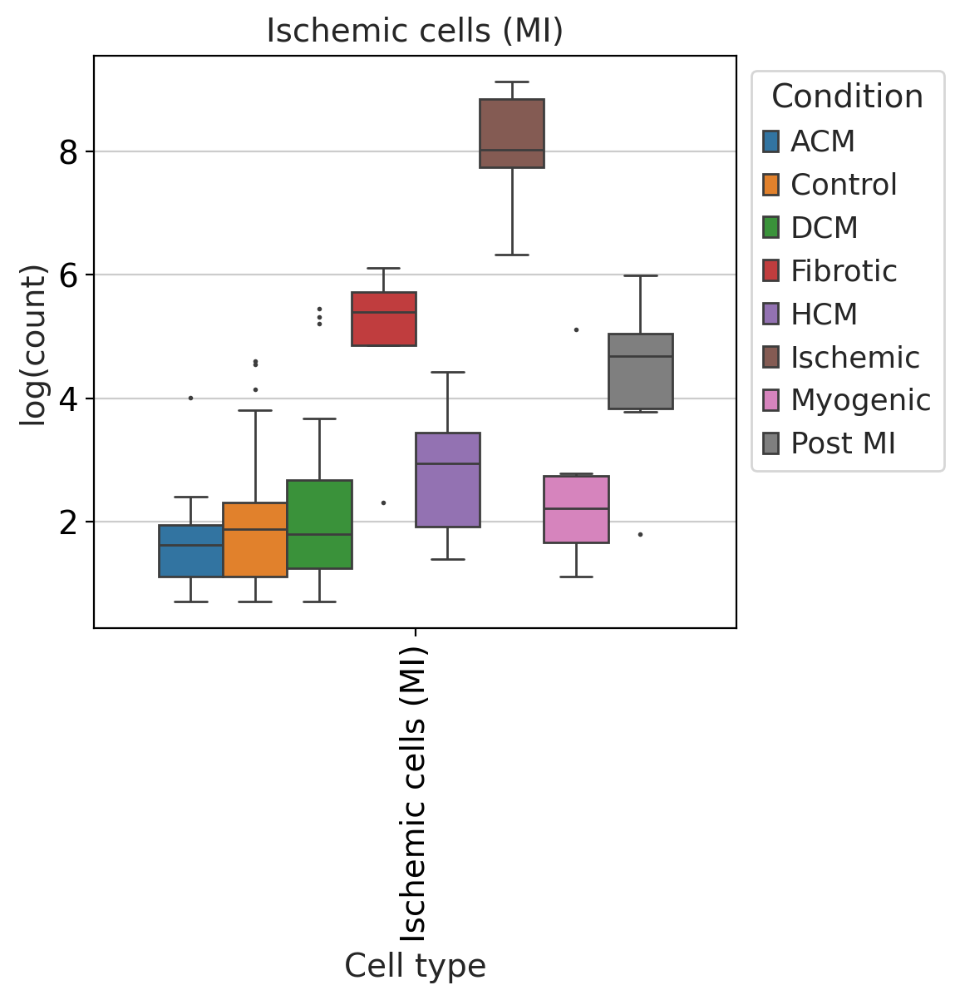

Endocardial


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

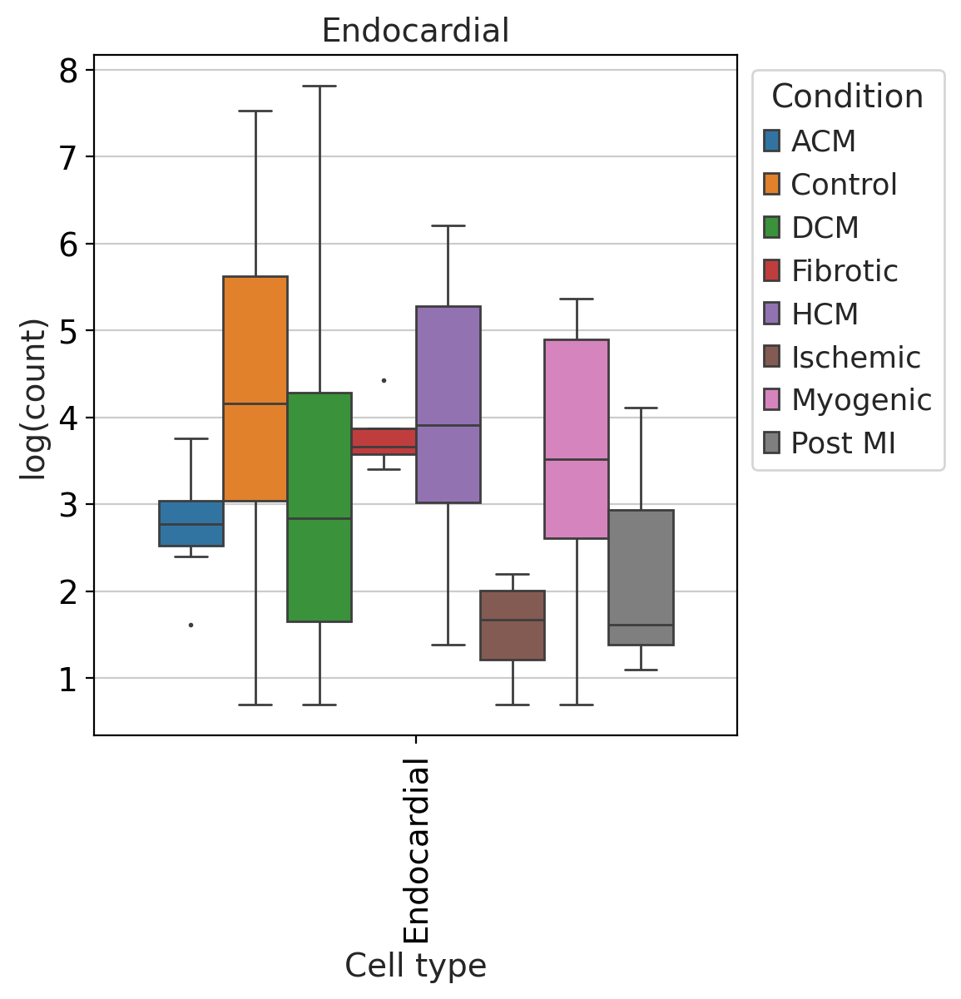

Epicardium


/home/uv525372/.local/lib/python3.10/site-packages/sccoda/util/data_visualization.py:335: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(cell_types, rotation=90)


<Figure size 640x480 with 0 Axes>

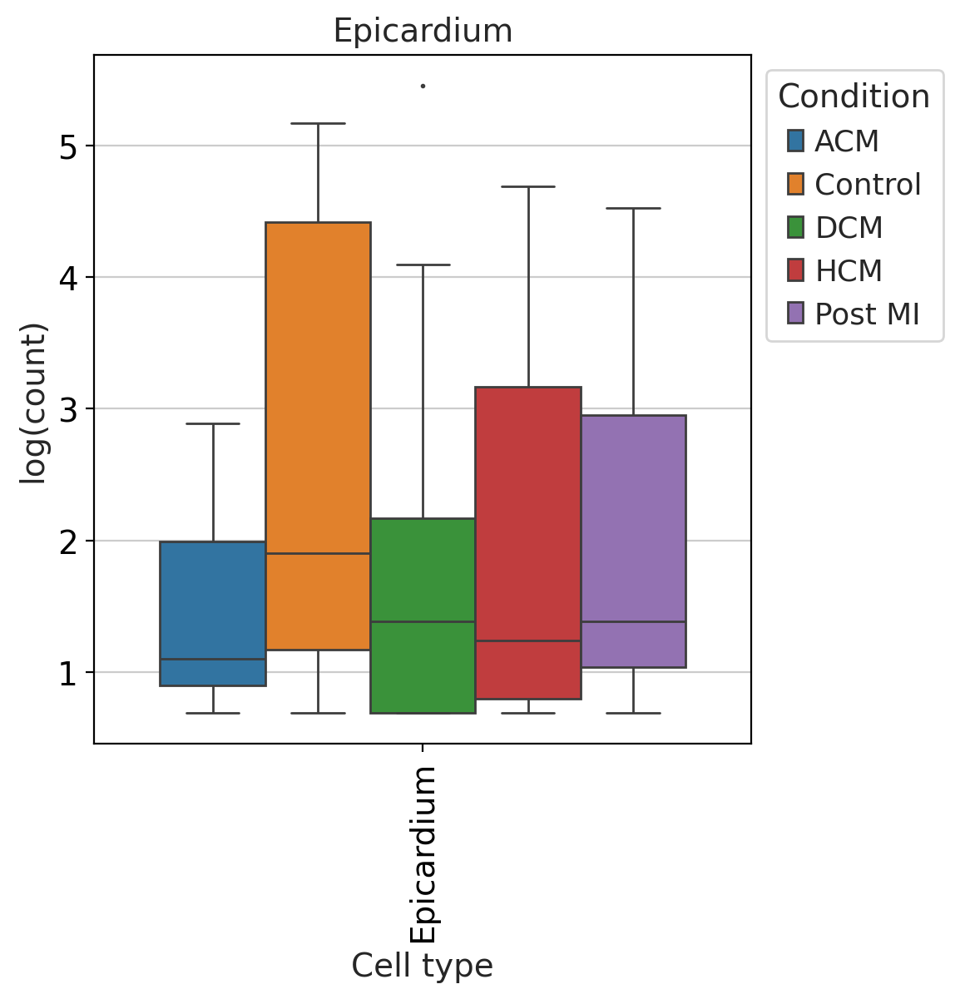

In [11]:
#pdf_pages = PdfPages('Boxplot_Annotation_log_counts.pdf')

for cluster in Heart.obs["Annotation_1"].unique():
    print(cluster)
    plt.figure(figsize=(8, 6))
    subset = Heart[Heart.obs["Annotation_1"].isin([cluster])]
    cross_table = pd.crosstab(index=[subset.obs["Donor"], subset.obs["Condition"]], columns=subset.obs["Annotation_1"])
    cell_counts = cross_table.reset_index()
    compositions = dat.from_pandas(cell_counts, covariate_columns=["Donor", "Condition"])
    viz.boxplots(compositions,feature_name="Condition",
    plot_facets=False,
    y_scale="log",
    add_dots=False,
    cmap="tab10")
    plt.title(cluster)
#    pdf_pages.savefig(plt.gcf(), bbox_inches='tight')
    plt.show()
#pdf_pages.close()

In [12]:
Heart.obs["celltype_batch"] = Heart.obs['Study'].astype(str) + ":" + Heart.obs['Cell_type'].astype(str)
df = Heart.obs.groupby(['Annotation_1','celltype_batch']).size().unstack(fill_value=0)

/w0/tmp/slurm_uv525372.61622081/ipykernel_2808228/1848639144.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = Heart.obs.groupby(['Annotation_1','celltype_batch']).size().unstack(fill_value=0)


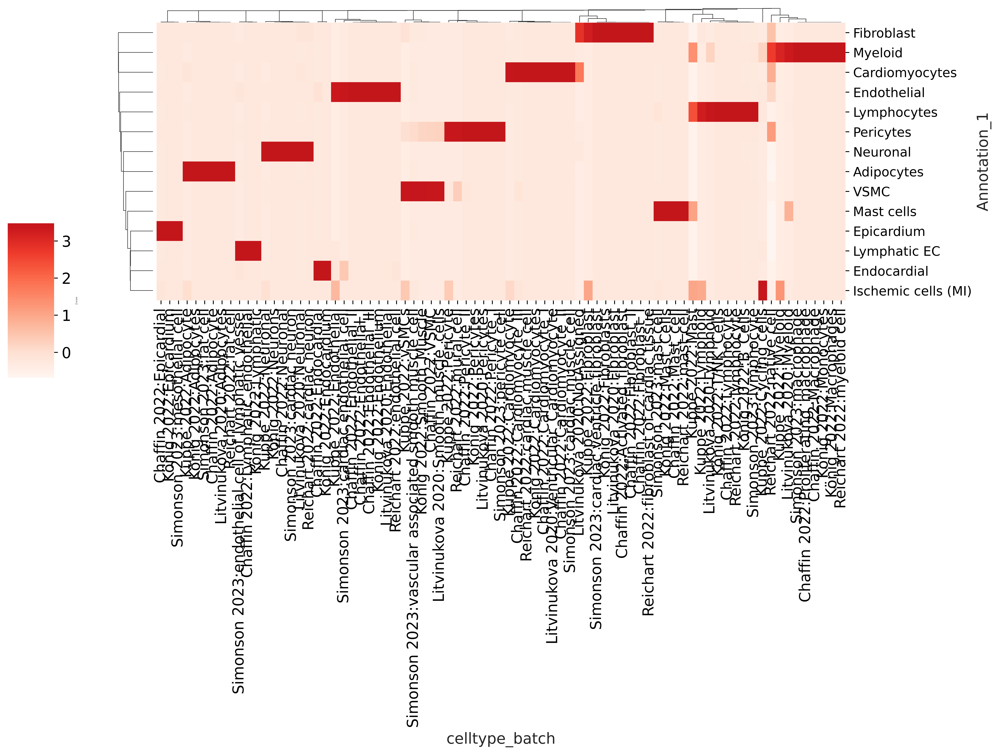

In [17]:
plt.rcParams["figure.dpi"] = 300
g = sns.clustermap(
    df,
    z_score=1,
    cmap="Reds",
    center=2,
    method='centroid',
    dendrogram_ratio=0.05,
    cbar_pos=(-0.1, 0.5, 0.05, 0.2),
    xticklabels=True,
    figsize=(12, 10)
)

# Increase y-tick label size
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_ymajorticklabels(), fontsize=12)

# Label the colorbar legend
g.ax_cbar.set_ylabel("Z-score", fontsize=2)

plt.show()